In [1]:
!pip -q install xgboost scikit-learn pandas numpy matplotlib seaborn

In [2]:

import os
import json
import zipfile
import requests
import glob
import io
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

DATA_DIR = "/content/ipl_data"
os.makedirs(DATA_DIR, exist_ok=True)

url = "https://cricsheet.org/downloads/ipl_json.zip"

response = requests.get(url, timeout=120)
response.raise_for_status()

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    z.extractall(DATA_DIR)

json_files = glob.glob(DATA_DIR + "/**/*.json", recursive=True)

print("JSON files downloaded:", len(json_files))
print("Data directory:", DATA_DIR)


JSON files downloaded: 1243
Data directory: /content/ipl_data


In [3]:

rows = []
match_metadata = []

def get_total_runs(delivery):
    return delivery.get("runs", {}).get("total", 0)

def is_legal_delivery(delivery):
    extras = delivery.get("extras", {})
    return (
        extras.get("wides", 0) == 0
        and extras.get("noballs", 0) == 0
    )

for file_path in json_files:
    try:
        with open(file_path, "r", encoding="utf-8") as f:
            match = json.load(f)

        info = match.get("info", {})

        if info.get("match_type") != "T20":
            continue

        if info.get("gender") != "male":
            continue

        outcome = info.get("outcome", {})
        winner = outcome.get("winner")

        # Exclude ties, no-results and other matches without a winner.
        if not winner or outcome.get("method") in ["D/L", "VJD"]:
            continue

        innings_list = match.get("innings", [])

        # Use only the first two innings; exclude super overs.
        if len(innings_list) < 2:
            continue

        first_innings_runs = 0
        first_innings_balls = 0
        first_innings_team = innings_list[0].get("team")

        for idx, innings in enumerate(innings_list[:2], start=1):
            batting_team = innings.get("team")
            bowling_team = next(
                (t for t in info.get("teams", []) if t != batting_team),
                None
            )

            if bowling_team is None:
                continue

            # The target is only known for the second innings.
            target = first_innings_runs + 1 if idx == 2 else np.nan

            total_runs = 0
            wickets = 0
            legal_balls = 0
            recent_runs = []
            innings_rows = []

            for over in innings.get("overs", []):
                for delivery in over.get("deliveries", []):
                    runs = get_total_runs(delivery)
                    legal = is_legal_delivery(delivery)

                    total_runs += runs

                    wickets_this_ball = delivery.get("wickets", [])
                    wickets += len(wickets_this_ball)

                    if legal:
                        legal_balls += 1

                    recent_runs.append(runs)
                    recent_runs = recent_runs[-6:]

                    balls_left = max(0, 120 - legal_balls)

                    if idx == 2:
                        runs_needed = max(0, target - total_runs)
                        required_rr = (
                            runs_needed * 6 / balls_left
                            if balls_left > 0 else 0
                        )
                        target_rr = (target - 1) / 20
                    else:
                        runs_needed = np.nan
                        required_rr = np.nan
                        target_rr = np.nan

                    current_rr = (
                        total_runs * 6 / legal_balls
                        if legal_balls > 0 else 0
                    )

                    # The label describes whether the current batting team
                    # ultimately wins the match.
                    innings_rows.append({
                        "match_id": os.path.basename(file_path),
                        "date": str(info.get("dates", [""])[0]),
                        "season": str(info.get("season", "")),
                        "venue": info.get("venue", "Unknown"),
                        "innings": idx,
                        "batting_team": batting_team,
                        "bowling_team": bowling_team,
                        "batter": delivery.get("batter", "Unknown"),
                        "bowler": delivery.get("bowler", "Unknown"),
                        "batter_runs": delivery.get("runs", {}).get("batter", 0),
                        "total_runs_ball": runs,
                        "wicket_ball": int(len(wickets_this_ball) > 0),
                        "total_runs": total_runs,
                        "wickets": wickets,
                        "legal_balls": legal_balls,
                        "balls_left": balls_left,
                        "current_rr": current_rr,
                        "target": target,
                        "runs_needed": runs_needed,
                        "required_rr": required_rr,
                        "target_rr": target_rr,
                        "recent_runs": sum(recent_runs),
                        "won": int(winner == batting_team),
                        "legal_delivery": int(legal)
                    })

            if idx == 1:
                first_innings_runs = total_runs
                first_innings_balls = legal_balls

            rows.extend(innings_rows)

    except Exception as e:
        print("Skipped file:", os.path.basename(file_path), str(e)[:100])

df = pd.DataFrame(rows)

print("Total ball-state rows:", len(df))
print("Unique matches:", df["match_id"].nunique())
display(df.head())


Total ball-state rows: 286621
Unique matches: 1195


,match_id,date,season,venue,innings,batting_team,bowling_team,batter,bowler,batter_runs,...,legal_balls,balls_left,current_rr,target,runs_needed,required_rr,target_rr,recent_runs,won,legal_delivery
0,1304104.json,2022-05-11,2022,"Dr DY Patil Sports Academy, Mumbai",1,Rajasthan Royals,Delhi Capitals,YBK Jaiswal,C Sakariya,1,...,1,119,6.0,NaN,NaN,NaN,NaN,1,0,1
1,1304104.json,2022-05-11,2022,"Dr DY Patil Sports Academy, Mumbai",1,Rajasthan Royals,Delhi Capitals,JC Buttler,C Sakariya,0,...,1,119,12.0,NaN,NaN,NaN,NaN,2,0,0
2,1304104.json,2022-05-11,2022,"Dr DY Patil Sports Academy, Mumbai",1,Rajasthan Royals,Delhi Capitals,JC Buttler,C Sakariya,1,...,2,118,9.0,NaN,NaN,NaN,NaN,3,0,1
3,1304104.json,2022-05-11,2022,"Dr DY Patil Sports Academy, Mumbai",1,Rajasthan Royals,Delhi Capitals,YBK Jaiswal,C Sakariya,1,...,3,117,8.0,NaN,NaN,NaN,NaN,4,0,1
4,1304104.json,2022-05-11,2022,"Dr DY Patil Sports Academy, Mumbai",1,Rajasthan Royals,Delhi Capitals,JC Buttler,C Sakariya,0,...,4,116,6.0,NaN,NaN,NaN,NaN,4,0,1


In [4]:

# Remove incomplete rows and implausible states.
df = df.dropna(subset=[
    "match_id", "innings", "total_runs", "wickets", "balls_left", "won"
]).copy()

df = df[
    df["innings"].isin([1, 2])
    & (df["legal_balls"] <= 120)
    & (df["wickets"] <= 10)
].copy()

# Cap extreme required run rates for numerical stability.
df["required_rr"] = df["required_rr"].clip(upper=60).fillna(0)
df["runs_needed"] = df["runs_needed"].fillna(0)
df["target_rr"] = df["target_rr"].fillna(0)

FEATURES = [
    "innings",
    "total_runs",
    "wickets",
    "legal_balls",
    "balls_left",
    "current_rr",
    "runs_needed",
    "required_rr",
    "target_rr",
    "recent_runs"
]

df[FEATURES] = df[FEATURES].replace(
    [np.inf, -np.inf], np.nan
).fillna(0)

print("Cleaned rows:", len(df))
print("Features:", FEATURES)
print("Class balance:")
print(df["won"].value_counts(normalize=True).round(3))


Cleaned rows: 286620
Features: ['innings', 'total_runs', 'wickets', 'legal_balls', 'balls_left', 'current_rr', 'runs_needed', 'required_rr', 'target_rr', 'recent_runs']
Class balance:
won
0    0.51
1    0.49
Name: proportion, dtype: float64


In [5]:

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    log_loss, brier_score_loss, accuracy_score,
    roc_auc_score
)
from xgboost import XGBClassifier

# Convert dates and sort matches chronologically.
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df.dropna(subset=["date"]).copy()

match_dates = (
    df.groupby("match_id")["date"]
    .min()
    .sort_values()
)

match_ids = match_dates.index.tolist()
cut = int(len(match_ids) * 0.80)

train_ids = set(match_ids[:cut])
test_ids = set(match_ids[cut:])

train = df[df["match_id"].isin(train_ids)].copy()
test = df[df["match_id"].isin(test_ids)].copy()

X_train = train[FEATURES]
y_train = train["won"].astype(int)

X_test = test[FEATURES]
y_test = test["won"].astype(int)

print("Training matches:", len(train_ids))
print("Testing matches:", len(test_ids))
print("Training rows:", len(train))
print("Testing rows:", len(test))

# Model 1: Logistic Regression baseline
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight=None
    ))
])

lr_model.fit(X_train, y_train)

# Model 2: XGBoost
xgb_model = XGBClassifier(
    n_estimators=350,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="binary:logistic",
    eval_metric="logloss",
    tree_method="hist",
    random_state=42,
    n_jobs=-1
)

xgb_model.fit(X_train, y_train)

print("Both models trained successfully.")


Training matches: 956
Testing matches: 239
Training rows: 229313
Testing rows: 57307
Both models trained successfully.


In [6]:

def evaluate_model(name, model, X, y):
    prob = model.predict_proba(X)[:, 1]
    pred = (prob >= 0.5).astype(int)

    return {
        "Model": name,
        "Log Loss": log_loss(y, prob, labels=[0, 1]),
        "Brier Score": brier_score_loss(y, prob),
        "Accuracy": accuracy_score(y, pred),
        "ROC-AUC": roc_auc_score(y, prob)
    }

results = pd.DataFrame([
    evaluate_model("Logistic Regression", lr_model, X_test, y_test),
    evaluate_model("XGBoost", xgb_model, X_test, y_test)
])

display(results.round(4))


,Model,Log Loss,Brier Score,Accuracy,ROC-AUC
0,Logistic Regression,0.5476,0.1870,0.7052,0.7894
1,XGBoost,0.6419,0.2045,0.6911,0.7688


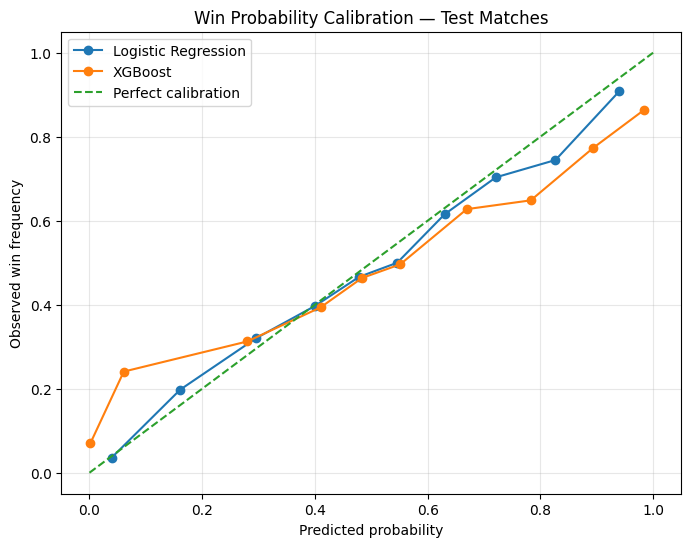

In [7]:

from sklearn.calibration import calibration_curve

plt.figure(figsize=(8, 6))

for name, model in [
    ("Logistic Regression", lr_model),
    ("XGBoost", xgb_model)
]:
    prob = model.predict_proba(X_test)[:, 1]
    actual, predicted = calibration_curve(
        y_test, prob, n_bins=10, strategy="quantile"
    )
    plt.plot(predicted, actual, marker="o", label=name)

plt.plot([0, 1], [0, 1], "--", label="Perfect calibration")
plt.xlabel("Predicted probability")
plt.ylabel("Observed win frequency")
plt.title("Win Probability Calibration — Test Matches")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [8]:

# Use XGBoost as the initial probability model.
# Later, use out-of-fold predictions for more rigorous player ratings.
df = df.sort_values(
    ["match_id", "innings", "legal_balls"]
).copy()

df["win_probability"] = xgb_model.predict_proba(
    df[FEATURES]
)[:, 1]

# 0 = far from a 50/50 match; 1 = exactly 50/50.
df["win_uncertainty"] = (
    1 - 2 * (df["win_probability"] - 0.5).abs()
).clip(0, 1)

# 0 at the start, approaching 1 at the end.
df["late_game_factor"] = (
    1 - df["balls_left"] / 120
).clip(0, 1)

# Chase difficulty, normalized to a value between 0 and 1.
df["chase_difficulty"] = (
    df["required_rr"] / 18
).clip(0, 1)

# Different weights for first innings and chase.
first_innings = df["innings"] == 1
second_innings = df["innings"] == 2

df["pressure_index"] = np.nan

df.loc[first_innings, "pressure_index"] = 100 * (
    0.65 * df.loc[first_innings, "win_uncertainty"]
    + 0.35 * df.loc[first_innings, "late_game_factor"]
)

df.loc[second_innings, "pressure_index"] = 100 * (
    0.45 * df.loc[second_innings, "win_uncertainty"]
    + 0.25 * df.loc[second_innings, "late_game_factor"]
    + 0.30 * df.loc[second_innings, "chase_difficulty"]
)

df["pressure_index"] = df["pressure_index"].clip(0, 100)

def pressure_category(score):
    if score >= 75:
        return "Extreme"
    elif score >= 50:
        return "High"
    elif score >= 25:
        return "Moderate"
    return "Low"

df["pressure_category"] = df["pressure_index"].apply(
    pressure_category
)

display(df[[
    "date", "batting_team", "innings", "total_runs",
    "wickets", "balls_left", "win_probability",
    "pressure_index", "pressure_category"
]].head(20).round(2))


,date,batting_team,innings,total_runs,wickets,balls_left,win_probability,pressure_index,pressure_category
22828,2017-04-05,Sunrisers Hyderabad,1,0,0,119,0.46,60.06,High
22829,2017-04-05,Sunrisers Hyderabad,1,0,0,118,0.46,60.35,High
22830,2017-04-05,Sunrisers Hyderabad,1,4,0,117,0.46,60.06,High
22831,2017-04-05,Sunrisers Hyderabad,1,4,0,116,0.46,61.33,High
22832,2017-04-05,Sunrisers Hyderabad,1,6,0,116,0.49,64.48,High
22833,2017-04-05,Sunrisers Hyderabad,1,6,0,115,0.48,64.14,High
22834,2017-04-05,Sunrisers Hyderabad,1,7,0,114,0.47,63.13,High
22835,2017-04-05,Sunrisers Hyderabad,1,8,0,113,0.48,64.06,High
22836,2017-04-05,Sunrisers Hyderabad,1,12,0,112,0.49,65.74,High
22837,2017-04-05,Sunrisers Hyderabad,1,13,0,112,0.51,65.99,High


In [9]:

df = df.sort_values(
    ["match_id", "innings", "legal_balls"]
).copy()

# Change in the current batting team's estimated win probability.
# Set the first observed delivery of each innings to zero because
# there is no previous delivery-state probability in this dataset.
df["previous_win_probability"] = (
    df.groupby(["match_id", "innings"])["win_probability"]
    .shift(1)
)

df["wpa"] = (
    df["win_probability"] - df["previous_win_probability"]
).fillna(0)

# High-pressure deliveries only.
high_pressure = df[df["pressure_index"] >= 70].copy()

def make_clutch_table(data, player_col, contribution_col, role,
                      minimum_balls=30, prior_balls=50):

    table = (
        data.groupby(player_col)
        .agg(
            pressure_balls=(contribution_col, "size"),
            total_wpa=(contribution_col, "sum"),
            mean_wpa=(contribution_col, "mean")
        )
        .reset_index()
        .rename(columns={player_col: "Player"})
    )

    # Empirical shrinkage toward a neutral score of zero.
    # This reduces extreme estimates for small samples.
    table["Clutch Rating"] = (
        table["mean_wpa"]
        * table["pressure_balls"]
        / (table["pressure_balls"] + prior_balls)
        * 1000
    )

    table["Role"] = role

    table = table[
        table["pressure_balls"] >= minimum_balls
    ]

    return table.sort_values(
        "Clutch Rating", ascending=False
    ).reset_index(drop=True)

batter_clutch = make_clutch_table(
    high_pressure,
    "batter",
    "wpa",
    "Batter"
)

# A bowling delivery that reduces the batting side's win
# probability receives positive bowling WPA.
high_pressure["bowler_wpa"] = -high_pressure["wpa"]

bowler_clutch = make_clutch_table(
    high_pressure,
    "bowler",
    "bowler_wpa",
    "Bowler"
)

print("TOP BATTERS UNDER PRESSURE")
display(batter_clutch.head(15).round(3))

print("TOP BOWLERS UNDER PRESSURE")
display(bowler_clutch.head(15).round(3))


TOP BATTERS UNDER PRESSURE


,Player,pressure_balls,total_wpa,mean_wpa,Clutch Rating,Role
0,Rashid Khan,123,1.549,0.013,8.952,Batter
1,Ashutosh Sharma,79,1.140,0.014,8.839,Batter
2,WG Jacks,41,0.705,0.017,7.745,Batter
3,M Vohra,129,0.837,0.006,4.678,Batter
4,JR Hopes,47,0.432,0.009,4.455,Batter
5,Shashank Singh,72,0.533,0.007,4.371,Batter
6,AD Russell,499,2.400,0.005,4.371,Batter
7,DB Ravi Teja,106,0.673,0.006,4.312,Batter
8,Y Venugopal Rao,255,1.171,0.005,3.840,Batter
9,AB de Villiers,1262,4.611,0.004,3.515,Batter


TOP BOWLERS UNDER PRESSURE


,Player,pressure_balls,total_wpa,mean_wpa,Clutch Rating,Role
0,C Bosch,30,0.715,0.024,8.937,Bowler
1,MP Yadav,37,0.566,0.015,6.510,Bowler
2,Mujeeb Ur Rahman,110,0.890,0.008,5.560,Bowler
3,J Little,59,0.568,0.010,5.214,Bowler
4,VY Mahesh,98,0.761,0.008,5.140,Bowler
5,DR Sams,107,0.800,0.007,5.096,Bowler
6,Mohsin Khan,112,0.750,0.007,4.630,Bowler
7,JJ Bumrah,893,4.260,0.005,4.517,Bowler
8,BAW Mendis,69,0.522,0.008,4.387,Bowler
9,M Pathirana,174,0.952,0.005,4.252,Bowler


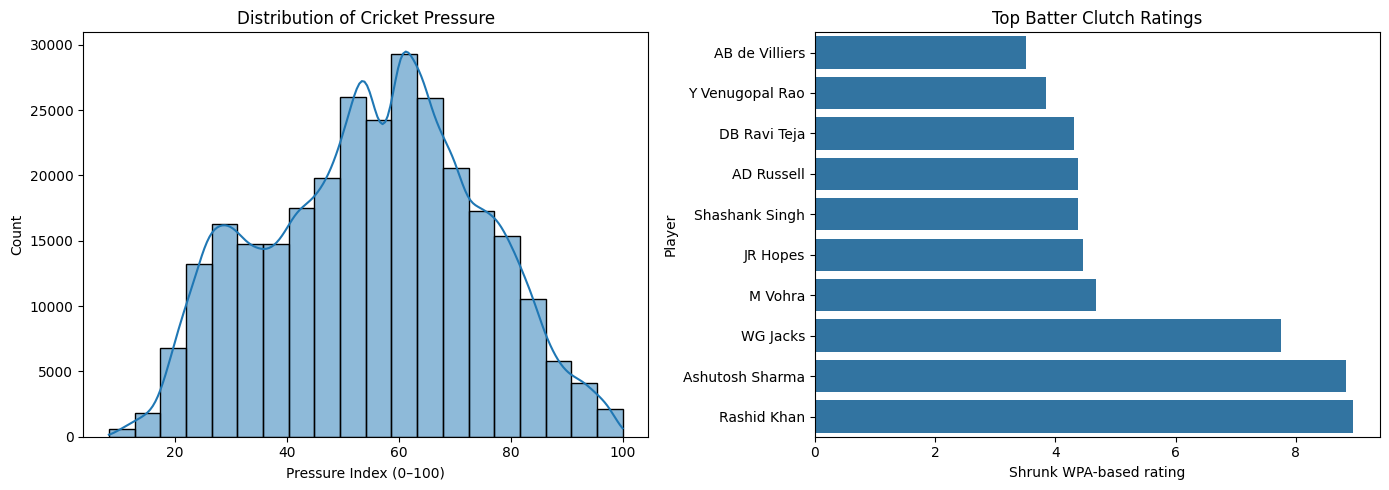

In [10]:

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df,
    x="pressure_index",
    bins=20,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Distribution of Cricket Pressure")
axes[0].set_xlabel("Pressure Index (0–100)")

top_batters = batter_clutch.head(10).sort_values("Clutch Rating")

if len(top_batters):
    sns.barplot(
        data=top_batters,
        x="Clutch Rating",
        y="Player",
        ax=axes[1]
    )

axes[1].set_title("Top Batter Clutch Ratings")
axes[1].set_xlabel("Shrunk WPA-based rating")

plt.tight_layout()
plt.show()


,match_id,date,teams,innings_count
1185,981001.json,2016-05-19,Kolkata Knight Riders vs Gujarat Lions,2
1186,981003.json,2016-05-20,Sunrisers Hyderabad vs Delhi Daredevils,2
1187,981005.json,2016-05-21,Kings XI Punjab vs Rising Pune Supergiants,2
1188,981007.json,2016-05-21,Mumbai Indians vs Gujarat Lions,2
1189,981009.json,2016-05-22,Kolkata Knight Riders vs Sunrisers Hyderabad,2
1190,981011.json,2016-05-22,Delhi Daredevils vs Royal Challengers Bangalore,2
1191,981013.json,2016-05-24,Gujarat Lions vs Royal Challengers Bangalore,2
1192,981015.json,2016-05-25,Sunrisers Hyderabad vs Kolkata Knight Riders,2
1193,981017.json,2016-05-27,Gujarat Lions vs Sunrisers Hyderabad,2
1194,981019.json,2016-05-29,Sunrisers Hyderabad vs Royal Challengers Banga...,2


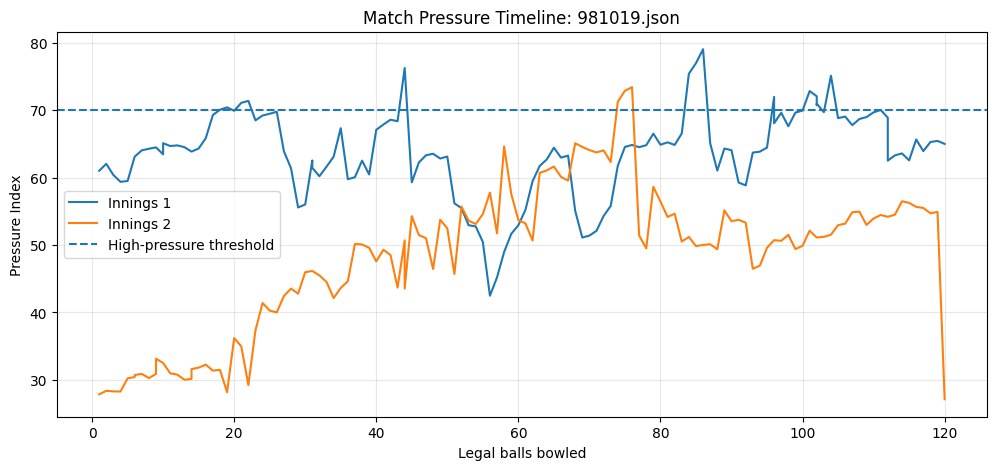

In [11]:

match_summary = (
    df[["match_id", "date", "batting_team", "innings"]]
    .drop_duplicates()
    .groupby("match_id")
    .agg(
        date=("date", "first"),
        teams=("batting_team", lambda x: " vs ".join(x.unique())),
        innings_count=("innings", "nunique")
    )
    .reset_index()
)

display(match_summary.tail(10))

# Select the latest match ID in the dataset.
selected_match = match_summary.iloc[-1]["match_id"]

match_data = df[df["match_id"] == selected_match].copy()

plt.figure(figsize=(12, 5))

for innings_num, group in match_data.groupby("innings"):
    plt.plot(
        group["legal_balls"],
        group["pressure_index"],
        label=f"Innings {innings_num}"
    )

plt.axhline(70, linestyle="--", label="High-pressure threshold")
plt.xlabel("Legal balls bowled")
plt.ylabel("Pressure Index")
plt.title(f"Match Pressure Timeline: {selected_match}")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [12]:

import joblib
import os

OUTPUT_DIR = "/content/rainfall_pressure_outputs".replace(
    "rainfall_pressure_outputs", "cricket_pressure_outputs"
)
os.makedirs(OUTPUT_DIR, exist_ok=True)

# Save trained model and feature names.
joblib.dump(
    {
        "model": xgb_model,
        "features": FEATURES,
        "pressure_threshold": 70
    },
    os.path.join(OUTPUT_DIR, "cricket_pressure_model.pkl")
)

# Export match-level delivery states and rankings.
df.to_csv(
    os.path.join(OUTPUT_DIR, "ball_by_ball_pressure.csv"),
    index=False
)

batter_clutch.to_csv(
    os.path.join(OUTPUT_DIR, "batter_clutch_ratings.csv"),
    index=False
)

bowler_clutch.to_csv(
    os.path.join(OUTPUT_DIR, "bowler_clutch_ratings.csv"),
    index=False
)

results.to_csv(
    os.path.join(OUTPUT_DIR, "model_evaluation.csv"),
    index=False
)

print("Saved files:")
for filename in os.listdir(OUTPUT_DIR):
    print(filename)


Saved files:
model_evaluation.csv
ball_by_ball_pressure.csv
cricket_pressure_model.pkl
bowler_clutch_ratings.csv
batter_clutch_ratings.csv


In [13]:

import shutil
from google.colab import files

zip_path = shutil.make_archive(
    "/content/cricket_pressure_outputs",
    "zip",
    OUTPUT_DIR
)

files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>